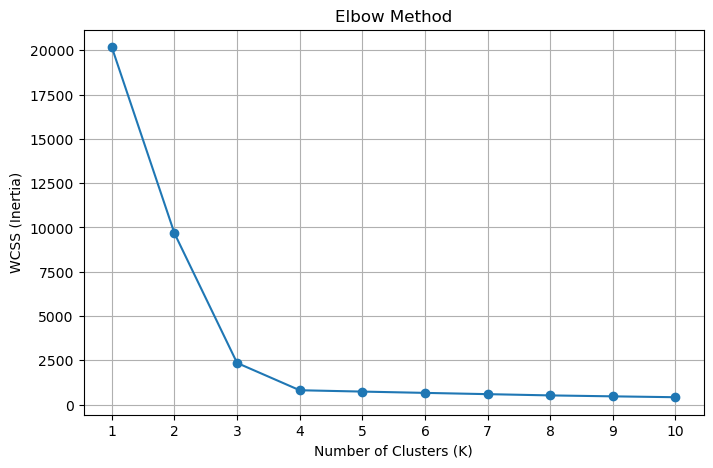

In [1]:
# K-Means Elbow Method
# Calculate WCSS for K values from 1 to 10 and plot the elbow curve.

import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate sample data
X, y = make_blobs(
    n_samples=300,
    centers=4,
    n_features=2,
    random_state=42,
    cluster_std=1.2
)

# Calculate WCSS for different K values
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    kmeans.fit(X)

    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.figure(figsize=(8, 5))

plt.plot(range(1, 11), wcss, marker="o")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Inertia)")
plt.title("Elbow Method")

plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

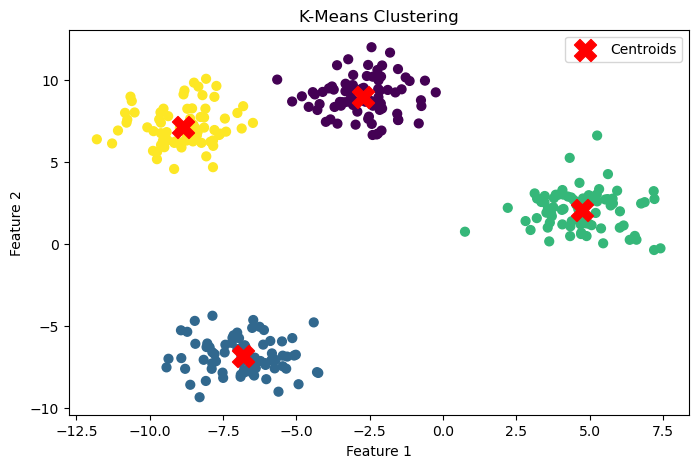

Centroids:
 [[-2.7332785   8.96731218]
 [-6.82289702 -6.82052706]
 [ 4.73387011  2.05552217]
 [-8.88062107  7.14479553]]


In [2]:
# K-Means Clustering
# Create four clusters and visualize their centroids.

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Train K-Means
kmeans = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42
)

# Fit and predict cluster labels
y_pred = kmeans.fit_predict(X)

# Get centroids
centroids = kmeans.cluster_centers_

# Visualize clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X[:, 0], X[:, 1],
    c=y_pred,
    cmap="viridis",
    s=40
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=250,
    color="red",
    label="Centroids"
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.legend()

plt.show()

print("Centroids:\n", centroids)

### knn from strach

In [3]:
# KNN Classification From Scratch
# Implement Euclidean distance, nearest neighbors, and majority voting.

import numpy as np
from collections import Counter


class KNN:

    def __init__(self, k=3):
        self.k = k

    # Calculate Euclidean distance
    def euclidean_distance(self, x1, x2):
        return np.sqrt(np.sum((x1 - x2) ** 2))

    # Store training data
    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train)
        self.y_train = np.asarray(y_train)

    # Predict class for one data point
    def predict_one(self, x):

        distances = []

        # Calculate distance from every training point
        for i in range(len(self.X_train)):

            distance = self.euclidean_distance(
                x, self.X_train[i]
            )

            distances.append((distance, self.y_train[i]))

        # Sort according to distance
        distances.sort(key=lambda item: item[0])

        # Select K nearest neighbors
        k_neighbors = distances[:self.k]

        # Extract their labels
        labels = [label for distance, label in k_neighbors]

        # Majority voting
        prediction = Counter(labels).most_common(1)[0][0]

        return prediction

    # Predict for multiple data points
    def predict(self, X_test):

        predictions = []

        for x in X_test:
            predictions.append(self.predict_one(x))

        return np.array(predictions)


# Example dataset
X_train = np.array([
    [1, 2],
    [2, 3],
    [3, 3],
    [6, 7],
    [7, 8],
    [8, 7]
])

y_train = np.array([0, 0, 0, 1, 1, 1])

# Test data
X_test = np.array([
    [2, 2],
    [7, 7]
])

# Create and train model
model = KNN(k=3)

model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

print("Predictions:", y_pred)

Predictions: [0 1]
